<h1 style="font-size:300%">🏠 HOUSE PRICE PREDICTOR</h1>

This notebook is a starting point for a regression model that predicts house prices based on features of those houses. It uses the Boston House price dataset which is included in this repo as a csv file and represents prices of houses in the city of Boston in the 1970s. The data for this example is included in the git repo, so you can just clone this repo and run the notebook.

Bas S.H.T. Michielsen, 2025

![banner](https://codeberg.org/Fontys/house_price_predictor/raw/branch/main/BANNER.jpg)

*Image by Stable Diffusion: a robot selling houses in Boston*

In [1]:
import csv, lightning, pandas, platform, os, seaborn, torch

from torch import nn
from torch.utils.data import TensorDataset, random_split
from lightning import LightningDataModule, LightningModule, Trainer
from torchmetrics.regression import R2Score
from lightning.pytorch.loggers import CSVLogger
from lightning.pytorch.callbacks import EarlyStopping

lightning.seed_everything(0)

torch.set_float32_matmul_precision('high') # Increase precision for Nvidia Tensor Cores.

data_path = "BostonHousing.csv"

print("Versions: python", platform.python_version(), "| torch", torch.__version__, "| lightning", lightning.__version__)

Seed set to 0


Versions: python 3.14.7 | torch 2.14.0+cpu | lightning 2.6.5


# ⛲ Data Source
The original source of the dataset is attributed to: Harrison, D., Rubinfeld, D.L., “Hedonic Prices and the Demand for Clean Air”, Journal of Environmental Economics & Management (5), 1978, pp. 81–102. The multivariate dataset is concerned with housing values in the suburbs of Boston. The dataset consists of 506 records with 13 continuous variables and 1 binary variable. The dependent variable is MEDV. There is no missing data. A description of each variable is provided below: 
 1. CRIM – per capita crime rate by town 
 2. ZN – proportion of residential land zoned for lots over 25,000 sq.ft. 
 3. INDUS – proportion of non–retail business acres per town 
 4. CHAS – Charles River dummy variable (1 if tract bounds river; 0 otherwise) 
 5. NOX – nitric oxides concentration (parts per 10 million) 
 6. RM – average number of rooms per dwelling 
 7. AGE – proportion of owner–occupied units built prior to 1940 
 8. DIS – weighted distances to five Boston employment centres 
 9. RAD – index of accessibility to radial highways 
 10. TAX – full-value property-tax rate per $10,000 
 11. PTRATIO – pupil-teacher ratio by town 
 12. B – 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town 
 13. LSTAT – % lower status of the population 
 14. MEDV – Median value of owner-occupied homes in $1000

In [2]:
df = pandas.read_csv(data_path)
print("The dataset contains", df.shape[0], "samples, in", df.shape[1], "columns.")
df.sample(20)

The dataset contains 506 samples, in 14 columns.


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
329,0.06724,0.0,3.24,0,0.460,6.333,17.2,5.2146,4,430,16.9,375.21,7.34,22.6
371,9.23230,0.0,18.10,0,0.631,6.216,100.0,1.1691,24,666,20.2,366.15,9.53,50.0
219,0.11425,0.0,13.89,1,0.550,6.373,92.4,3.3633,5,276,16.4,393.74,10.50,23.0
403,24.80170,0.0,18.10,0,0.693,5.349,96.0,1.7028,24,666,20.2,396.90,19.77,8.3
78,0.05646,0.0,12.83,0,0.437,6.232,53.7,5.0141,5,398,18.7,386.40,12.34,21.2
15,0.62739,0.0,8.14,0,0.538,5.834,56.5,4.4986,4,307,21.0,395.62,8.47,19.9
487,4.83567,0.0,18.10,0,0.583,5.905,53.2,3.1523,24,666,20.2,388.22,11.45,20.6
340,0.06151,0.0,5.19,0,0.515,5.968,58.5,4.8122,5,224,20.2,396.90,9.29,18.7
310,2.63548,0.0,9.90,0,0.544,4.973,37.8,2.5194,4,304,18.4,350.45,12.64,16.1
102,0.22876,0.0,8.56,0,0.520,6.405,85.4,2.7147,5,384,20.9,70.80,10.63,18.6


# 🛠️ Data Preprocessing

The first thing to do is create a torch Dataset object from the provided csv file. Here we use pandas to load the csv file into a DataFrame and then that DataFrame is used to put the data in a TensorDataset. A TensorDataset is a structure that contains a tensor of values as features and a tensor of values as target. Of our data the last column is the target and all the other columns are the features.

In [3]:
class TabularDataset(TensorDataset):
    """TabularDataSet loads data from a pandas DataFrame assuming the last column is the target and all other columns are features that can be converted to float."""
    def __init__(self, dataframe):
        rows = dataframe.values.astype(float)
        data = torch.tensor(rows, dtype=torch.float32)
        super().__init__(data[:, :-1], data[:, -1])
    
    def num_features(self) -> int:
        return self[0][0].size()[0]

dataset = TabularDataset(df)
print("Created a TabularDataset with", len(dataset), "samples, and", dataset.num_features(), "features.")

Created a TabularDataset with 506 samples, and 13 features.


To train a model, different dataset are needed, first there should be data for training purposes. However, to judge how well the model is fitted we also need data for validation and later for testing purposes. It is a common approach to split the dataset in three parts named `train`, `val` and `test` often in way that a resonably sized validation set and test set are created and the remaining data becoming the train set. For PyTorch Lightning, these three sets are then put together in something called a DataModule.

Note that you can increase `batch_size` or `num_workers` to speed up the process if you find that running this notebook is slow on your computer. However, doing so requires more CPU cores and/or more RAM so at some point you may reach a limit and things may break. The provided values of `batch_size=32` and `num_workers=0` is a safe default that is unlikely to produce errors.

In [4]:
train, val, test = random_split(dataset, [.6, .3, .1])
datamodule = LightningDataModule.from_datasets(train, val, test, batch_size=32, num_workers=0)
print("Created a DataModule with:", len(datamodule.train_dataloader().dataset), "training items,", len(datamodule.val_dataloader().dataset), "validation items and", len(datamodule.test_dataloader().dataset), "test items.")

Created a DataModule with: 304 training items, 152 validation items and 50 test items.


# 🧬 Modelling

Of course there are many ways to define the model that is going to be trained. This example, though perhaps not the best model in the world, is rather simple and serves as an easy way of getting started with PyTorch Lightning. Here we create a simple feedforward neural network. The model consists of two layers defined in a sequential manner. First, we have a linear layer that takes in the features and transforms them into 64 nodes. This is followed by a ReLU (Rectified Linear Unit) activation function, which introduces non-linearity to the model, allowing it to learn more complex patterns. Finally, the output layer reduces the 64 nodes down to a single output, making this model suitable for regression tasks where we want to predict a single, however, continuous variable. 

In [5]:
class RegressionModel(LightningModule):
    def __init__(self, num_features):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(num_features, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )
        self.criterion = nn.MSELoss()
        self.r2 = R2Score()
    
    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=0.005)

    def forward(self, X):
        return self.model(X).view(-1)

    def training_step(self, batch):
        X, y = batch
        logits = self(X)
        return self.criterion(logits, y)
    
    def validation_step(self, batch):
        X, y = batch
        logits = self(X)
        loss = self.criterion(logits, y)
        self.log("val_loss", loss)

    def test_step(self, batch):
        X, y = batch
        logits = self(X)
        self.log("test_r2", self.r2(logits, y), on_step=False, on_epoch=True)

    def predict_step(self, batch):
        X, y = batch
        return self(X)

model = RegressionModel(num_features=dataset.num_features())

Here we use a PyTorch Lightning Trainer to fit the model using the DataModule that we defined earlier. Internally it will iterate epochs, meaning that it will go through all train data to learn about relationships between the features and the target and then run a validation to gauge its performance which is measured in validation loss, meaning the difference between the true values and the model's predicted values. Here the assumption is that if the validation loss does no longer go down, the model is fitted as best as possible and continue training makes no improvements. We define an EarlyStopping for this that monitors when `val_loss` reaches its minimum. If so, it stops training.

In [6]:
logger = CSVLogger(save_dir=".")
stop = EarlyStopping(monitor="val_loss", mode="min")
trainer = Trainer(logger=logger, max_epochs=-1, callbacks=[stop], log_every_n_steps=10)
trainer.fit(model, datamodule=datamodule)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

  | Name      | Type       | Params | Mode  | FLOPs
---------------------------------------------------------
0 | model     | Sequential | 961    | train | 0    
1 | criterion | MSELoss    | 0      | train | 0    
2 | r2        | R2Score    | 0      | train | 0    
---------------------------------------------------------
961       Trainable params
0         Non-trainable params
961       Total params
0.004     Total estimated model params size (MB)
6         Modules in train mode
0  

c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does no

Epoch 16: 100%|██████████| 10/10 [00:00<00:00, 86.19it/s, v_num=2] 


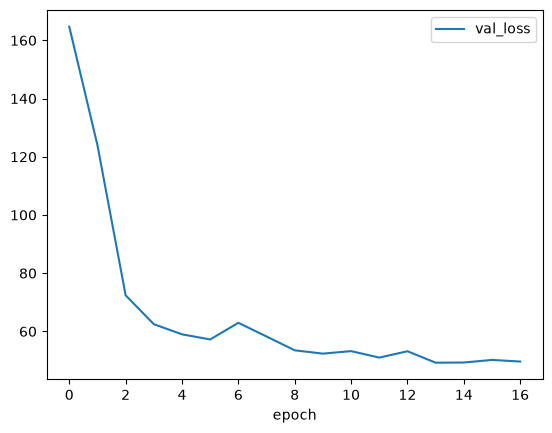

In [7]:
metrics = pandas.read_csv(os.path.join(trainer.log_dir, "metrics.csv"))
plot = metrics[["epoch", "val_loss"]].set_index("epoch").plot()

Given that the `val_loss` has flatlined (it is no longer going down), the early stop callback has stopped the training process.

# 🔬 Evaluation

Now let's run the model against the test data and get an indication for how well it is performing. A typical metric for regression models is R-squared which is the proportion of the variation in the target that is predictable from the features. In other words, how well can the target be predicted using the features. An R-squared closer to 0.0 is worse and closer to 1.0 is better.

In [8]:
score = trainer.test(model, datamodule=datamodule)

c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Testing DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 41.66it/s] 
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
         test_r2            0.3122735321521759
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


A regplot shows how well the predictions of the model align with the truth values. Dots on or close ot the line are good predictions whereas if dots are scatterd away from the line it indicates that our model is not doing well. The shaded area represents the expected confidence interval and dots within the shaded area are considered close to the line. Morever, this plot shows that our model does reasonably well for houses priced between 15000 and 30000 but does a bit less good for houses that are more expensive or cheaper, as dots appear farther away from the line in those price ranges.

c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 232.90it/s]


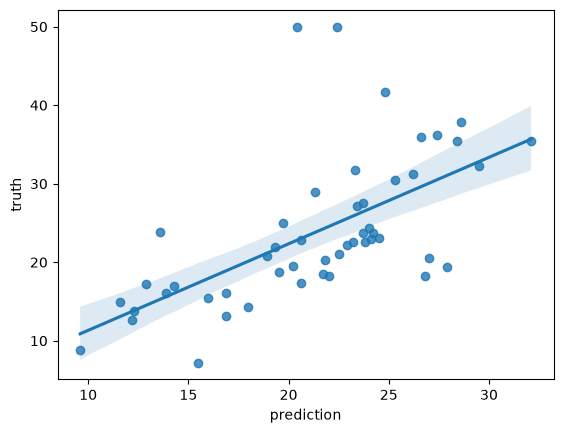

In [9]:
dataloader = datamodule.test_dataloader()
output = trainer.predict(model, dataloaders=dataloader)
predictions = torch.cat(output)
results = [[round(truth[1].item(),1), round(prediction.item(),1)] for truth, prediction in zip(dataloader.dataset, predictions)]
df = pandas.DataFrame(results, columns=["truth", "prediction"])
plot = seaborn.regplot(data=df, y="truth", x="prediction")

Here we print out all truth values, predicted values and the error (absolute difference between them) for all 50 items in the test data.

In [10]:
df["error"] = abs(df["truth"] - df["prediction"])
df

,truth,prediction,error
0,18.5,21.7,3.2
1,27.1,23.4,3.7
2,22.6,23.2,0.6
3,14.3,18.0,3.7
4,25.0,19.7,5.3
5,17.2,12.9,4.3
6,21.0,22.5,1.5
7,18.2,26.8,8.6
8,23.1,24.5,1.4
9,16.1,16.9,0.8


# 🚀 Inference

Now it is time to see how this model does for any new input. Feel free to change the values below and see the prediction of the model.

In [11]:
data = {
    "crim": 0.00632,
    "zn": 18.0,
    "indus": 2.31,
    "chas": 0.5,
    "nox": 0.538,
    "rm": 5.575,
    "age": 65.2,
    "dis": 3.09,
    "rad": 1.0,
    "tax": 250.5,
    "ptratio": 15.3,
    "b": 399.9,
    "lstat": 3.98,
}
data = torch.tensor(list(data.values()), dtype=torch.float32)
model.eval()
pred = model(data)
print("The estimated price for your house is: $", round(pred.item() *1000, 2))

The estimated price for your house is: $ 28144.13
